# 02 · Models

The models planned in `01-Research-and-Plan.ipynb`: the shared scoring, the baselines and two versions of
ridge regression on averaged FinBERT vectors, with how they compare with the published results. The
attention network will be added here next (plan, section 3.2). The reasons for each choice are in
notebook 01; this notebook is the build and the results.

The whole notebook runs in about 3 minutes on a 4-core laptop CPU.

## 1. Setup

Runs locally or on Colab. On Colab the cell connects Google Drive, gets the repo from GitHub, and copies
`data.pkl` from `MyDrive/sprint2-data` onto the Colab machine's disk (reading straight from Drive is
very slow). Locally it does nothing.

In [1]:
import importlib.util, os, shutil, subprocess
from pathlib import Path

NOTEBOOK_DIR = "Alex"
if importlib.util.find_spec("google.colab") is not None:
    from google.colab import drive
    drive.mount("/content/drive")
    repo = Path("/content/dst-sprint2")
    if repo.exists():
        subprocess.run(["git", "-C", str(repo), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/Oscar339/dst-sprint2.git", str(repo)], check=True)
    processed = repo / "data" / "processed"
    processed.mkdir(parents=True, exist_ok=True)
    if not (processed / "data.pkl").exists():
        shutil.copy(Path("/content/drive/MyDrive/sprint2-data/data.pkl"), processed / "data.pkl")
    os.chdir(repo / NOTEBOOK_DIR)

In [2]:
import pickle, sys, time, platform
sys.path.insert(0, ".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy import stats
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler

import scoring

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
with open("../data/processed/data.pkl", "rb") as f:   # Oscar's hand-over file (Oscar/make_handover.py)
    d = pickle.load(f)
df = scoring.frame(d)
print(f"{len(df):,} reports, {df.year.min()}-{df.year.max()}, X {d['X'].shape}")

Python 3.13.17 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1


27,142 reports, 1996-2006, X (27142, 1536)


## 2. Check: log volatility is the right scale

`01-Research-and-Plan.ipynb` (section 2.1) argued for scoring on log volatility because raw volatility is skewed. Skewness is 0 for a
symmetric distribution; above 1 is strongly right-skewed.

In [3]:
vol = np.exp(df["logvol_after"])
print(f"skewness of volatility:     {stats.skew(vol):.2f}")
print(f"skewness of log volatility: {stats.skew(df['logvol_after']):.2f}")
top = vol.sort_values(ascending=False)
share = (top.iloc[:len(top) // 100] - vol.mean()).pow(2).sum() / (vol - vol.mean()).pow(2).sum()
print(f"share of raw volatility's total squared spread from the most volatile 1% of reports: {share:.0%}")

skewness of volatility:     3.33
skewness of log volatility: 0.08
share of raw volatility's total squared spread from the most volatile 1% of reports: 32%


## 3. The training windows

In [4]:
rows = []
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        train, test = scoring.masks(df, T, window)
        years = sorted(df.loc[train, "year"].unique())
        rows.append({"window": window, "test_year": T, "train_years": f"{years[0]}–{years[-1]}",
                     "train_reports": int(train.sum()), "test_reports": int(test.sum())})
windows_table = pd.DataFrame(rows)

# The paper and strict windows must match the shared splits from report/02-Data.ipynb.
shared = pd.read_csv("../data/output/splits.csv")
check = windows_table.merge(shared, on=["test_year", "window"], suffixes=("", "_shared"))
assert len(check) == 12 and (check.train_years == check.train_years_shared).all() \
    and (check.train_reports == check.train_reports_shared).all()
print("paper and strict windows match data/output/splits.csv")

windows_table.pivot(index="test_year", columns="window", values="train_reports")[list(scoring.WINDOWS)]

paper and strict windows match data/output/splits.csv


window,paper,strict,last year,all prior
test_year,,,,
2001,9747,7596,2220,7596
2002,10788,8489,2151,9747
2003,11399,8812,2299,12046
2004,12474,9257,2587,14633
2005,13422,10254,3217,17850
2006,14392,11271,3168,21018


For 2001 the *strict* and *all prior* windows are the same (1996–1999), because the data starts in 1996.

## 4. Baselines

"Same as last year" scored against the straight line, which is the baseline every later model is compared with.

In [5]:
copy_vs_line = scoring.evaluate(df, scoring.predict_copy, name="copy last year")
line_mse = copy_vs_line.pivot(index="test_year", columns="window", values="baseline_mse")[list(scoring.WINDOWS)]
print("MSE of the straight-line baseline, by training window:")
display(line_mse.round(4))
print("MSE of 'same as last year' (no training):")
display(copy_vs_line.query("window == 'paper'").set_index("test_year")["mse"].round(4).to_frame("copy"))

MSE of the straight-line baseline, by training window:


window,paper,strict,last year,all prior
test_year,,,,
2001,0.1684,0.1669,0.1668,0.1669
2002,0.1368,0.1469,0.1424,0.1423
2003,0.1758,0.1886,0.1067,0.1761
2004,0.0937,0.1089,0.1014,0.1215
2005,0.0884,0.0889,0.1011,0.0956
2006,0.0982,0.0995,0.1000,0.1009


MSE of 'same as last year' (no training):


,copy
test_year,
2001,0.1468
2002,0.1334
2003,0.1550
2004,0.1092
2005,0.0971
2006,0.1034


## 5. Fitting ridge fast: per-year sums (Map/Reduce)

The project needs many ridge fits: 2 versions × 3 inputs × 4 windows × 6 test years = 144. My first
version used scikit-learn's `RidgeCV`, which decomposes the whole training matrix in every fit (up to
21,000 reports × 1,536 numbers). That took about 15 seconds a fit and **40 minutes** for the notebook
on a 4-core laptop. Too slow to rerun on Colab or for a marker.

**Ridge only needs a few sums over the training reports.** The ridge solution
$\hat\beta = (X^\top X + \lambda I)^{-1} X^\top r$ depends on the data only through $X^\top X$ (a
$p \times p$ matrix), $X^\top r$, and a handful of totals. The same holds for everything around it:

- **Standardising:** the means are $X^\top \mathbf 1 / n$, and the variances are the diagonal of the
  centred $X^\top X$ divided by $n$.
- **The target:** it is the straight line's residual $r = y - a - b\,x$. Its sums follow from stored ones,
  for example $X^\top r = X^\top y - a\, X^\top \mathbf 1 - b\, X^\top x$. So one set of sums serves the
  line of every window.
- **Choosing $\lambda$:** generalised cross-validation (Golub, Heath & Wahba, 1979) replaces each
  leave-one-out factor $1 - h_{ii}$ by its average $1 - \operatorname{tr}(H)/n$:
  $$\text{GCV}(\lambda) = \frac{n \cdot \text{RSS}(\lambda)}{\big(n - \operatorname{tr} H_\lambda\big)^2},
  \qquad \operatorname{tr} H_\lambda = \sum_j \frac{s_j}{s_j + \lambda},$$
  where $s_j$ are the eigenvalues of the standardised $X^\top X$. RSS also comes from the sums, so one
  eigen-decomposition gives the whole curve.
- **Within-year centring** (section 8): subtracting a year's mean from its rows changes its sums to
  $X^\top X - n_y \mu_y \mu_y^\top$, which also needs only that year's sums.

**Sums add up.** That is what makes this Map/Reduce (lecture 9.2):

- **map:** compute the sums for each filing year independently (11 small jobs);
- **reduce:** add the sums of the years in a training window;
- **fit:** one eigen-decomposition of a $p \times p$ matrix ($p$ = 768 or 1,536).

| Step | Cost | Depends on the number of reports $n$? |
|---|---|---|
| `RidgeCV`, every fit | $O(n p^2)$ | yes, every time |
| map: per-year sums, once | $O(n p^2)$ in total | yes, but once, and split across years or machines |
| reduce + fit, every fit | $O(Y p^2 + p^3)$ for $Y$ years | **no** |

At 1000× the reports, the map step grows 1000× but splits across as many machines as there are chunks
of data, and every fit after that costs the same as now. The code is in `Alex/ridge_sums.py`. The sums
for "both" contain Item 1 and Item 7 as sub-blocks, so they are computed once.

**Check against scikit-learn.** Below, four fits, two windows × both versions, with `RidgeCV` and with
the sums.

In [6]:
import ridge_sums

X1, X7 = d["X"][:, :768], d["X"][:, 768:]          # data.pkl: Item 1's averaged chunks, then Item 7's
INPUTS = {"Item 1": X1, "Item 7": X7, "both": d["X"]}

t = time.perf_counter()
SUMS_BOTH = ridge_sums.year_sums(INPUTS["both"], df)                     # map: one job per filing year
SUMS = {"both": SUMS_BOTH,
        "Item 1": ridge_sums.subset(SUMS_BOTH, np.arange(0, 768)),       # sub-blocks, no new pass
        "Item 7": ridge_sums.subset(SUMS_BOTH, np.arange(768, 1536))}
print(f"map step: per-year sums for 11 years in {time.perf_counter() - t:.1f}s")

ALPHAS = np.logspace(0, 7, 29)

def demean_by_year(a, years):
    return a - pd.DataFrame(a).groupby(years).transform("mean").to_numpy()

x_all, y_all, yr_all = df["logvol_before"].to_numpy(), df["logvol_after"].to_numpy(), df["year"].to_numpy()
rows = []
for window, T in [("paper", 2006), ("last year", 2003)]:
    train, test = scoring.masks(df, T, window)
    a, b = scoring.fit_line(df, train)
    for within in [False, True]:
        r, X_train, X_test = y_all[train] - (a + b * x_all[train]), X7[train], X7[test]
        if within:
            r = demean_by_year(r[:, None], yr_all[train])[:, 0]
            X_train, X_test = demean_by_year(X_train, yr_all[train]), X_test - X_test.mean(axis=0)
        t = time.perf_counter()
        scaler = StandardScaler().fit(X_train)
        sk = RidgeCV(alphas=ALPHAS).fit(scaler.transform(X_train), r)
        p_sk = sk.predict(scaler.transform(X_test))
        t_sk = time.perf_counter() - t
        t = time.perf_counter()
        fast = ridge_sums.fit(SUMS["Item 7"], sorted(set(yr_all[train])), a, b, ALPHAS, within_year=within)
        p_fast = ridge_sums.predict(fast, X7[test])
        t_fast = time.perf_counter() - t
        same = ridge_sums.predict(ridge_sums.fit(SUMS["Item 7"], sorted(set(yr_all[train])), a, b, [sk.alpha_],
                                                 within_year=within), X7[test])
        rows.append({"window": window, "test_year": T, "version": "within-year" if within else "first attempt",
                     "lambda RidgeCV": sk.alpha_, "lambda sums (GCV)": fast["alpha"],
                     "largest prediction difference, same lambda": np.abs(same - p_sk).max(),
                     "seconds RidgeCV": round(t_sk, 1), "seconds sums": round(t_fast, 2)})
pd.DataFrame(rows)

map step: per-year sums for 11 years in 1.1s


,window,test_year,version,lambda RidgeCV,lambda sums (GCV),"largest prediction difference, same lambda",seconds RidgeCV,seconds sums
0,paper,2006,first attempt,3162.277660,3162.277660,7.697509e-08,8.4,0.16
1,paper,2006,within-year,5623.413252,5623.413252,5.373996e-08,8.8,0.21
2,last year,2003,first attempt,1778.279410,1778.279410,1.005756e-07,1.8,0.15
3,last year,2003,within-year,1778.279410,1778.279410,7.432201e-08,1.7,0.73


Both methods choose the same $\lambda$ in every case here, and with the same $\lambda$ the predictions
agree to about $10^{-12}$, rounding error. So the algebra is right. Each fit takes about a second
instead of 5–20. Section 10 compares all 144 fits with the earlier `RidgeCV` run.

## 6. First attempt: ridge on averaged FinBERT vectors

Two stages as planned in `01-Research-and-Plan.ipynb` (section 2.5): the straight line on last year's volatility, then ridge on the
standardised averaged chunk vectors to the line's residual. All training years in a window are fitted
together, with one intercept.

In [7]:
chosen = []   # the lambda picked in each fit, to check it is not at the edge of the grid

def make_ridge(label, within_year):
    def predict(df, train, test):
        a, b = scoring.fit_line(df, train)
        model = ridge_sums.fit(SUMS[label], sorted(set(yr_all[train])), a, b, ALPHAS, within_year=within_year)
        chosen.append({"model": "within-year" if within_year else "first attempt", "input": label,
                       "alpha": model["alpha"]})
        return a + b * x_all[test] + ridge_sums.predict(model, INPUTS[label][test])
    return predict

t = time.perf_counter()
ridge_results = pd.concat([scoring.evaluate(df, make_ridge(label, within_year=False), name=f"ridge, {label}")
                           for label in INPUTS], ignore_index=True)
print(f"{len(ridge_results)} fits in {time.perf_counter() - t:.0f}s")

72 fits in 77s


Each row of the summary is one model and window, over the six test years. *Change in MSE* is relative
to the straight line (negative = better). *Years better* counts test years where the model's MSE is
lower; *years significant* counts those whose whole 95% interval is below zero.

In [8]:
def summarise(results, change="change_pct", high="ci_high"):
    return (results.groupby(["model", "window"], sort=False)
            .agg(mean_change_pct=(change, "mean"), best_year_pct=(change, "min"), worst_year_pct=(change, "max"),
                 years_better=(change, lambda d: int((d < 0).sum())),
                 years_significant=(high, lambda h: int((h < 0).sum())))
            .round(1))

summarise(pd.concat([copy_vs_line, ridge_results], ignore_index=True))

mean_change_pct  best_year_pct  worst_year_pct  \
model          window                                                      
copy last year paper                  0.7          -12.8            16.6   
               strict                -4.3          -17.8             9.2   
               last year              5.7          -12.0            45.3   
               all prior             -6.1          -12.0             2.4   
ridge, Item 1  paper                 -0.7          -15.1             8.2   
               strict                 1.3          -17.2            11.2   
               last year              4.7           -0.6            11.4   
               all prior             -0.2          -12.0            10.8   
ridge, Item 7  paper                 -1.7          -18.2            13.0   
               strict                 1.0          -27.3            22.4   
               last year              4.9           -1.2            12.6   
               all prior             -2.2          -21.4             9.4   
ridge, both    paper                 -1.2          -19.4            13.9   
               strict                 2.1          -29.3            27.3   
               last year              6.2            0.3            15.8   
               all prior             -0.4          -22.2            12.7   

                          years_better  years_significant  
model          window                                      
copy last year paper                 3                  3  
               strict                3                  3  
               last year             3                  2  
               all prior             4                  4  
ridge, Item 1  paper                 3                  2  
               strict                2                  2  
               last year             1                  0  
               all prior             3                  2  
ridge, Item 7  paper                 3                  3  
               strict                2                  2  
               last year             1                  0  
               all prior             2                  2  
ridge, both    paper                 3                  2  
               strict                2                  2  
               last year             0                  0  
               all prior             2                  2

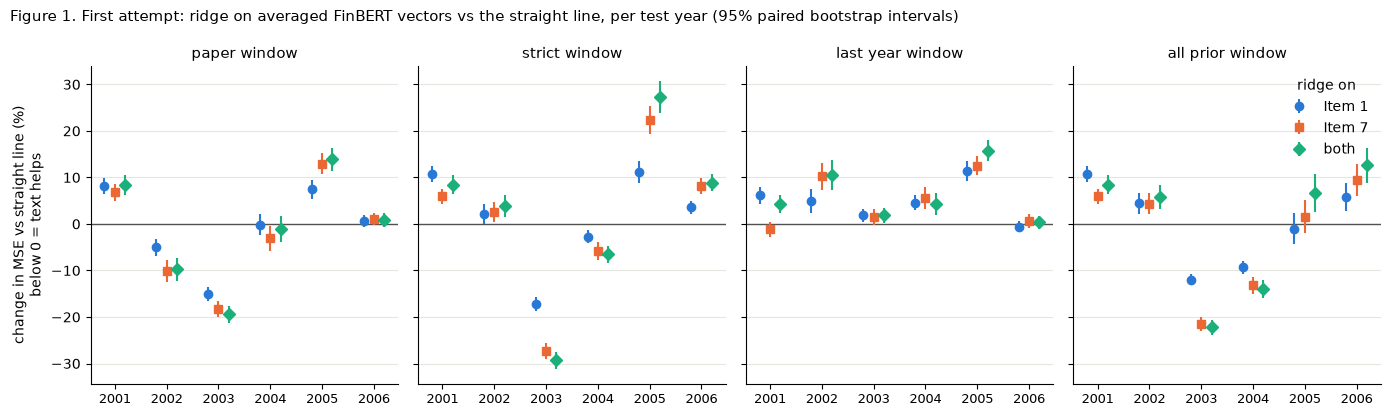

In [9]:
COLORS = {"Item 1": "#2a78d6", "Item 7": "#eb6834", "both": "#1baf7a"}   # fixed order: series 1, 2, 3
MARKERS = {"Item 1": "o", "Item 7": "s", "both": "D"}                    # second cue besides colour
OFFSET = {"Item 1": -0.2, "Item 7": 0.0, "both": 0.2}

def plot_changes(results, prefix, title, change="change_pct", lo_col=None, hi_col=None):
    fig, axes = plt.subplots(1, 4, figsize=(14, 4.2), sharey=True)
    for ax, window in zip(axes, scoring.WINDOWS):
        ax.axhline(0, color="#52514e", lw=1)
        for label in INPUTS:
            r = results[(results.model == f"{prefix}, {label}") & (results.window == window)]
            pct = r[change]
            lo = r[lo_col] if lo_col else 100 * r.ci_low / r.baseline_mse
            hi = r[hi_col] if hi_col else 100 * r.ci_high / r.baseline_mse
            ax.errorbar(r.test_year + OFFSET[label], pct, yerr=[pct - lo, hi - pct], fmt=MARKERS[label],
                        color=COLORS[label], ms=6, lw=1.5, capsize=0, label=label)
        ax.set_title(f"{window} window", fontsize=11)
        ax.set_xticks(list(scoring.TEST_YEARS))
        ax.tick_params(axis="x", labelsize=9)
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("change in MSE vs straight line (%)\nbelow 0 = text helps")
    axes[-1].legend(title="ridge on", frameon=False, loc="best")
    fig.suptitle(title, fontsize=11, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

plot_changes(ridge_results, "ridge",
             "Figure 1. First attempt: ridge on averaged FinBERT vectors vs the straight line, per test year (95% paired bootstrap intervals)")

**This does not look like a model that has learnt something steady.** The same model is 29% better than
the baseline in one year and 24% worse in another, and the intervals are narrow in both directions.
Even the two-parameter straight line has very different errors depending on its training window
(section 4: for 2003, 0.107 to 0.189). Something that is the same for every company in a year is
moving the scores.

## 7. Why the scores swing: the level and the spread

For any set of errors $e_i = y_i - \hat y_i$ on a test year, the MSE splits exactly into two parts:
$$\text{MSE} = \frac1n\sum_i e_i^2 = \underbrace{\bar e^{\,2}}_{\text{level}} + \underbrace{\frac1n\sum_i (e_i - \bar e)^2}_{\text{spread}} .$$

- **Level:** how far off the model is about the *whole year's* average volatility. It is one number per
  year, shared by every company: the market's mood, which a single company's report cannot know.
- **Spread:** how well the model separates riskier from safer companies *within* the year. This is the
  part the text of an individual report could plausibly help with.

Average log volatility moves a lot from year to year: it rose to the 2000–02 crash and then fell
steadily to 2006. A model trained on high-volatility years predicts too high a level for the calm years
after.

In [10]:
print("average log volatility after filing, by year:")
print(df.groupby("year")["logvol_after"].mean().round(2).to_frame().T.to_string())

lvl = copy_vs_line.assign(level_share=lambda r: 100 * r.baseline_level / r.baseline_mse)
print("\nshare of the straight line's MSE that is the level part (%):")
display(lvl.pivot(index="window", columns="test_year", values="level_share").loc[list(scoring.WINDOWS)].round(0))

split = ridge_results.assign(level_change=lambda r: 100 * (r.level - r.baseline_level) / r.baseline_mse,
                             spread_change=lambda r: 100 * (r.spread - r.baseline_spread) / r.baseline_mse)
print("first-attempt ridge on Item 7, change in MSE vs the straight line split into its two parts "
      "(percentage points of the line's MSE):")
display(split[split.model == "ridge, Item 7"].pivot(index="window", columns="test_year",
        values=["level_change", "spread_change"]).loc[list(scoring.WINDOWS)].round(1))

average log volatility after filing, by year:
year          1996  1997  1998  1999  2000  2001  2002  2003  2004  2005  2006
logvol_after -3.44 -3.36 -3.14  -3.1 -3.05  -3.2 -3.24 -3.55  -3.7 -3.77 -3.81

share of the straight line's MSE that is the level part (%):


test_year,2001,2002,2003,2004,2005,2006
window,,,,,,
paper,30.0,4.0,44.0,8.0,0.0,1.0
strict,29.0,11.0,48.0,22.0,0.0,2.0
last year,29.0,9.0,7.0,15.0,14.0,2.0
all prior,29.0,9.0,44.0,31.0,8.0,3.0


first-attempt ridge on Item 7, change in MSE vs the straight line split into its two parts (percentage points of the line's MSE):


level_change                              spread_change            \
test_year         2001  2002  2003  2004  2005 2006          2001 2002 2003   
window                                                                        
paper              8.8  -4.4 -19.6  -8.0   8.7  1.5          -1.9 -5.8  1.3   
strict             7.7   7.0 -27.7 -11.7  16.8  7.2          -1.8 -4.4  0.4   
last year         -0.6  10.7  -0.7  -4.7  10.7  1.3          -0.6 -0.5  2.2   
all prior          7.7   8.3 -22.2 -17.9  -1.7  6.1          -1.8 -3.9  0.8   

                           
test_year  2004 2005 2006  
window                     
paper       5.0  4.3 -0.4  
strict      6.0  5.6  0.9  
last year  10.3  1.8 -0.6  
all prior   4.8  3.3  3.3

## 8. Second version: ridge within each year

The first attempt fits all the training years together. Language in 10-Ks drifts over time, so the
averaged text vectors partly say *which era* a report is from. Ridge can then use the text to guess the
year's level, a coincidence of the training years rather than anything about the company, which helps in
some test years and hurts in others.

The fix is to let the text explain only differences **within a year**:

1. fit the straight line as before; it alone sets the level of the prediction;
2. in the training data, subtract each year's average from the residual *and* from the text vectors, so
   that what ridge sees has no year-to-year differences left to learn;
3. at test time, centre the text vectors on the test year's average. This uses other companies' *text*
   from the same year (never their volatility). In real use it would be the average of the reports
   filed so far that year.

The text part then has an average of exactly zero in every test year, so the model can only change how
companies are ranked against each other, never the year's level. With the per-year sums, the centring
is the $X^\top X - n_y \mu_y \mu_y^\top$ correction of section 5, done year by year.

In [11]:
t = time.perf_counter()
within_results = pd.concat([scoring.evaluate(df, make_ridge(label, within_year=True), name=f"within-year ridge, {label}")
                            for label in INPUTS], ignore_index=True)
print(f"{len(within_results)} fits in {time.perf_counter() - t:.0f}s")

ch = pd.DataFrame(chosen)
print(f"lambda chosen: {ch.alpha.min():.3g} to {ch.alpha.max():.3g} (grid {ALPHAS.min():.0e} to {ALPHAS.max():.0e}); "
      f"at an edge of the grid: {ch.alpha.isin([ALPHAS.min(), ALPHAS.max()]).sum()} of {len(ch)}")
summarise(within_results)

72 fits in 71s
lambda chosen: 1e+03 to 1e+04 (grid 1e+00 to 1e+07); at an edge of the grid: 0 of 144


mean_change_pct  best_year_pct  \
model                     window                                      
within-year ridge, Item 1 paper                  0.3           -3.3   
                          strict                 1.1           -1.7   
                          last year              2.5           -1.2   
                          all prior              0.8           -1.8   
within-year ridge, Item 7 paper                 -0.6           -5.9   
                          strict                 0.3           -4.3   
                          last year              2.1           -0.6   
                          all prior             -0.1           -4.0   
within-year ridge, both   paper                 -0.1           -5.8   
                          strict                 0.9           -3.5   
                          last year              2.6           -1.1   
                          all prior              0.4           -3.4   

                                     worst_year_pct  years_better  \
model                     window                                    
within-year ridge, Item 1 paper                 3.5             3   
                          strict                5.1             3   
                          last year             6.4             1   
                          all prior             4.7             3   
within-year ridge, Item 7 paper                 2.4             3   
                          strict                4.8             2   
                          last year            10.3             3   
                          all prior             3.7             3   
within-year ridge, both   paper                 3.4             3   
                          strict                6.1             2   
                          last year            10.2             1   
                          all prior             5.0             3   

                                     years_significant  
model                     window                        
within-year ridge, Item 1 paper                      1  
                          strict                     0  
                          last year                  0  
                          all prior                  1  
within-year ridge, Item 7 paper                      2  
                          strict                     2  
                          last year                  0  
                          all prior                  2  
within-year ridge, both   paper                      1  
                          strict                     1  
                          last year                  0  
                          all prior                  1

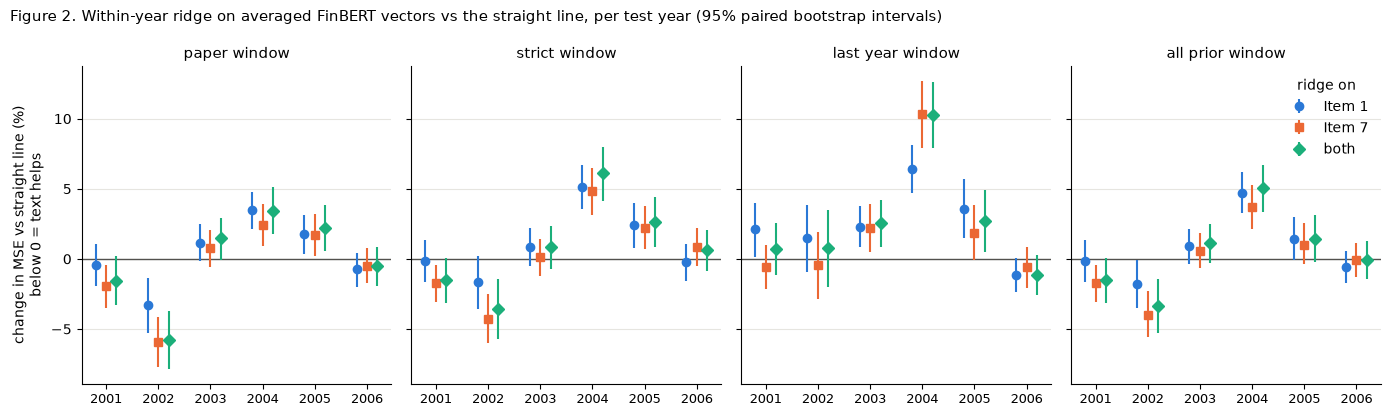

In [12]:
plot_changes(within_results, "within-year ridge",
             "Figure 2. Within-year ridge on averaged FinBERT vectors vs the straight line, per test year (95% paired bootstrap intervals)")

In [13]:
# Per year, for the record: % change in MSE vs the straight line, with the 95% interval.
detail = within_results.assign(
    pct=lambda r: r.change_pct.round(1).astype(str) + "% [" + (100 * r.ci_low / r.baseline_mse).round(1).astype(str)
                  + ", " + (100 * r.ci_high / r.baseline_mse).round(1).astype(str) + "]")
detail.pivot(index=["model", "window"], columns="test_year", values="pct").loc[
    [(m, w) for m in within_results.model.unique() for w in scoring.WINDOWS]]

test_year                                          2001                2002  \
model                     window                                              
within-year ridge, Item 1 paper       -0.4% [-1.9, 1.0]  -3.3% [-5.3, -1.3]   
                          strict      -0.1% [-1.6, 1.3]   -1.7% [-3.6, 0.2]   
                          last year     2.1% [0.1, 4.0]    1.5% [-1.0, 3.9]   
                          all prior   -0.1% [-1.6, 1.3]  -1.8% [-3.5, -0.1]   
within-year ridge, Item 7 paper      -1.9% [-3.5, -0.4]  -5.9% [-7.7, -4.1]   
                          strict     -1.7% [-3.1, -0.4]  -4.3% [-6.0, -2.5]   
                          last year   -0.6% [-2.1, 1.0]   -0.5% [-2.9, 1.9]   
                          all prior  -1.7% [-3.1, -0.4]  -4.0% [-5.6, -2.3]   
within-year ridge, both   paper       -1.5% [-3.3, 0.2]  -5.8% [-7.9, -3.7]   
                          strict      -1.5% [-3.1, 0.1]  -3.5% [-5.7, -1.5]   
                          last year    0.7% [-1.2, 2.6]    0.8% [-2.0, 3.5]   
                          all prior   -1.5% [-3.1, 0.1]  -3.4% [-5.3, -1.5]   

test_year                                        2003               2004  \
model                     window                                           
within-year ridge, Item 1 paper      1.2% [-0.2, 2.5]    3.5% [2.2, 4.8]   
                          strict     0.9% [-0.5, 2.2]    5.1% [3.5, 6.7]   
                          last year   2.3% [0.8, 3.7]    6.4% [4.7, 8.1]   
                          all prior  0.9% [-0.4, 2.1]    4.7% [3.3, 6.2]   
within-year ridge, Item 7 paper      0.7% [-0.6, 2.1]    2.4% [0.9, 3.9]   
                          strict     0.1% [-1.2, 1.4]    4.8% [3.1, 6.5]   
                          last year   2.2% [0.5, 3.9]  10.3% [7.9, 12.7]   
                          all prior  0.6% [-0.6, 1.8]    3.7% [2.2, 5.2]   
within-year ridge, both   paper      1.5% [-0.1, 2.9]    3.4% [1.8, 5.1]   
                          strict     0.9% [-0.7, 2.4]    6.1% [4.2, 8.0]   
                          last year   2.6% [0.9, 4.2]  10.2% [7.9, 12.6]   
                          all prior  1.1% [-0.3, 2.5]    5.0% [3.4, 6.7]   

test_year                                        2005               2006  
model                     window                                          
within-year ridge, Item 1 paper       1.8% [0.4, 3.2]  -0.7% [-2.0, 0.5]  
                          strict      2.4% [0.8, 4.0]  -0.2% [-1.6, 1.1]  
                          last year   3.6% [1.5, 5.7]  -1.2% [-2.4, 0.0]  
                          all prior  1.4% [-0.1, 3.0]  -0.6% [-1.7, 0.5]  
within-year ridge, Item 7 paper       1.7% [0.2, 3.2]  -0.5% [-1.7, 0.7]  
                          strict      2.2% [0.7, 3.8]   0.9% [-0.5, 2.2]  
                          last year  1.8% [-0.1, 3.8]  -0.6% [-2.1, 0.9]  
                          all prior  1.0% [-0.4, 2.6]  -0.1% [-1.3, 1.1]  
within-year ridge, both   paper       2.2% [0.6, 3.9]  -0.5% [-1.9, 0.9]  
                          strict      2.6% [0.9, 4.4]   0.6% [-0.8, 2.1]  
                          last year   2.7% [0.5, 4.9]  -1.1% [-2.6, 0.2]  
                          all prior  1.4% [-0.2, 3.2]  -0.1% [-1.4, 1.3]

## 9. Comparison with the papers: the same reports, or not?

Kogan et al. (2009, Table 2) report for 2006 an MSE of 0.1463 for last year's volatility alone and
0.1402 for text plus history. Their "baseline" is simply copying last year's log volatility, so it can
be recomputed exactly from their public label files. Below I do that three ways: on **all** their public
reports, on **ours** (the 89% matched to EDGAR-CORPUS, `report/02`), and on the **dropped** 11%.

In [14]:
import urllib.request

kogan_dir = Path("../data/raw/kogan")                 # same place Oscar/02-Merge-Kogan-EDGAR.ipynb downloads to
kogan_dir.mkdir(parents=True, exist_ok=True)
for yr in range(1996, 2007):
    for f in ["logvol.-12.txt", "logvol.+12.txt"]:
        target = kogan_dir / f"{yr}.{f}"
        if not target.exists():
            urllib.request.urlretrieve(f"https://www.cs.cmu.edu/~ark/10K/data/{target.name}", target)

def read_logvol(yr, sign):
    return (pd.read_csv(kogan_dir / f"{yr}.logvol.{sign}12.txt", sep=" ", header=None, names=["v", "key"])
            .drop_duplicates("key").set_index("key")["v"])

PAPER = {2001: (2596, 0.1747), 2002: (2846, 0.1600), 2003: (3612, 0.1873),     # Kogan et al. (2009), Table 2:
         2004: (3559, 0.1442), 2005: (3474, 0.1365), 2006: (3308, 0.1463)}     # (test reports, baseline MSE)
rows = []
for yr in scoring.TEST_YEARS:
    k = pd.DataFrame({"before": read_logvol(yr, "-"), "after": read_logvol(yr, "+")}).dropna()
    se = (k["after"] - k["before"]) ** 2
    ours = k.index.isin(df["key"])
    rows.append({"test_year": yr, "paper: reports": PAPER[yr][0], "paper: copy MSE": PAPER[yr][1],
                 "public: reports": len(k), "public: copy MSE": se.mean(),
                 "ours: reports": int(ours.sum()), "ours: copy MSE": se[ours].mean(),
                 "dropped: reports": int((~ours).sum()), "dropped: copy MSE": se[~ours].mean(),
                 "ours: mean logvol": k["after"][ours].mean(), "dropped: mean logvol": k["after"][~ours].mean()})
coverage = pd.DataFrame(rows).set_index("test_year")
coverage.round(4)

,paper: reports,paper: copy MSE,public: reports,public: copy MSE,ours: reports,ours: copy MSE,dropped: reports,dropped: copy MSE,ours: mean logvol,dropped: mean logvol
test_year,,,,,,,,,,
2001,2596,0.1747,2596,0.1747,2299,0.1468,297,0.3905,-3.1990,-3.0154
2002,2846,0.1600,2845,0.1600,2587,0.1334,258,0.4273,-3.2356,-3.1786
2003,3612,0.1873,3611,0.1873,3217,0.1550,394,0.4512,-3.5477,-3.5043
2004,3559,0.1442,3558,0.1442,3168,0.1092,390,0.4285,-3.6996,-3.7429
2005,3474,0.1365,3474,0.1365,3121,0.0971,353,0.4847,-3.7689,-3.8031
2006,3308,0.1463,3306,0.1464,3003,0.1034,303,0.5729,-3.8077,-3.9423


**What this shows.**

- On all public reports, copying last year's volatility gives **exactly the paper's numbers** (0.1747,
  0.1600, 0.1873, 0.1442, 0.1365, 0.1464). The data and the scoring are the same as theirs. This is also the
  0.1464 in `Oscar/PLAN.md`.
- On **our** reports the same baseline is 16–29% lower (0.1034 in 2006). The reports we dropped have
  **3–6 times the error**: their volatility changed much more between the two years.
- Their *average* volatility is close to ours, which is why a check on volatility levels finds no
  selection bias. But the thing we predict is the **change** from last year, and on that the dropped
  reports are very different. They are the hard cases.

**Consequences.**

1. **Our MSEs cannot be compared with the paper's directly.** Comparisons must be relative to a
   baseline computed on the *same* reports: change in MSE against copying last year's volatility.
2. **The same trap applies to later work.** FETILDA (Xia et al., 2022, Table 5) reports MSEs around 0.09
   for 2006 on 2,564 test reports, a different subset from Kogan's 3,308, and calls it a 27% improvement
   over Kogan's baseline of 0.1464 on the full set. On our data, dropping the unmatched reports alone
   lowers that baseline by 29%, with no model. We cannot check their test set, but an improvement of that
   size is what a different subset of reports can produce by itself.
3. **Our conclusions hold only for reports with clean EDGAR sections.** Item 7 could be added for the
   dropped reports from Kogan's own text, which exists for all of them (Item 1 could not). That would let
   the Item 7 models be scored on Kogan's full test sets.

**Our models against the paper's, both relative to copying last year on their own reports:**

In [15]:
KOGAN = {"TF+ (Kogan)":             [0.1885, 0.1616, 0.1925, 0.1230, 0.1272, 0.1402],   # Table 2, text + history
         "LOG1P+ bigrams (Kogan)":  [0.1852, 0.1792, 0.1599, 0.1352, 0.1307, 0.1448]}
rel = {name: [100 * (m / PAPER[yr][1] - 1) for m, yr in zip(v, scoring.TEST_YEARS)] for name, v in KOGAN.items()}

all_results = pd.concat([copy_vs_line, ridge_results, within_results], ignore_index=True)
all_results.to_csv("../data/output/alex-02-ridge-results.csv", index=False)   # for the report and other notebooks
paper_w = all_results[all_results.window == "paper"]
copy_mse = paper_w[paper_w.model == "copy last year"].set_index("test_year")["mse"]
for name in ["copy last year", "ridge, Item 7", "within-year ridge, Item 7", "within-year ridge, both"]:
    m = paper_w[paper_w.model == name].set_index("test_year")
    model_mse = m["baseline_mse"] if name == "copy last year" else m["mse"]   # for this row: the straight line
    rel[("straight line" if name == "copy last year" else name) + " (ours)"] = list(100 * (model_mse / copy_mse - 1))
print("change in MSE vs copying last year's volatility (%), paper window, negative = better:")
pd.DataFrame(rel, index=list(scoring.TEST_YEARS)).T.round(1)

change in MSE vs copying last year's volatility (%), paper window, negative = better:


,2001,2002,2003,2004,2005,2006
TF+ (Kogan),7.9,1.0,2.8,-14.7,-6.8,-4.2
LOG1P+ bigrams (Kogan),6.0,12.0,-14.6,-6.2,-4.2,-1.0
straight line (ours),14.7,2.6,13.4,-14.2,-9.0,-5.0
"ridge, Item 7 (ours)",22.6,-7.8,-7.3,-16.8,2.8,-3.9
"within-year ridge, Item 7 (ours)",12.5,-3.4,14.3,-12.2,-7.4,-5.4
"within-year ridge, both (ours)",12.9,-3.3,15.1,-11.3,-7.0,-5.5


On our reports, our straight line, with **no text at all**, has nearly the same pattern against copying
as Kogan's text models: worse in 2001–03, better in 2004–06. Their paper has no working fitted
history-only model to compare with (its "SVR on v(−12) with bias" scores 5.68 in 2006, Table 2). Since the
line needs only the labels, which exist for every public report, I fit it on **Kogan's full public data**
with their training window, for a like-for-like comparison with their Table 2:

In [16]:
full = pd.concat([pd.DataFrame({"before": read_logvol(yr, "-"), "after": read_logvol(yr, "+"), "year": yr}).dropna()
                  for yr in range(1996, 2007)])
rows = []
for i, T in enumerate(scoring.TEST_YEARS):
    tr, te = full[full.year.between(T - 5, T - 1)], full[full.year == T]
    b, a = np.polyfit(tr["before"], tr["after"], 1)
    line = np.mean((te["after"] - (a + b * te["before"])) ** 2)
    rows.append({"test_year": T, "test reports": len(te), "copy (paper's baseline)": PAPER[T][1],
                 "straight line, no text": line, "TF+ (Kogan, text + history)": KOGAN["TF+ (Kogan)"][i],
                 "LOG1P+ bigrams (Kogan)": KOGAN["LOG1P+ bigrams (Kogan)"][i], "line slope": b})
full_line = pd.DataFrame(rows).set_index("test_year")
full_line["text beyond the line, TF+ (%)"] = 100 * (full_line["TF+ (Kogan, text + history)"] / full_line["straight line, no text"] - 1)
full_line.round(4)

,test reports,copy (paper's baseline),"straight line, no text","TF+ (Kogan, text + history)",LOG1P+ bigrams (Kogan),line slope,"text beyond the line, TF+ (%)"
test_year,,,,,,,
2001,2596,0.1747,0.1922,0.1885,0.1852,0.8913,-1.9199
2002,2845,0.1600,0.1631,0.1616,0.1792,0.8630,-0.8981
2003,3611,0.1873,0.2040,0.1925,0.1599,0.8694,-5.6248
2004,3558,0.1442,0.1272,0.1230,0.1352,0.9144,-3.3327
2005,3474,0.1365,0.1275,0.1272,0.1307,0.9027,-0.2084
2006,3306,0.1463,0.1403,0.1402,0.1448,0.8629,-0.0942


**This changes how the paper's result reads.** On Kogan's own data and training years, the two-number
straight line reaches 0.1403 in 2006 against TF+'s 0.1402, and 0.1275 against 0.1272 in 2005. In 2004–06,
nearly all of the improvement the paper reports over copying last year comes from **fitting** last
year's volatility, not from the text. The fitted slope is about 0.86–0.91, so extreme volatilities are
pulled towards the average. Measured against the line, TF+ adds 0–6% depending on the year (most in
2003–04, almost nothing in 2005–06). LOG1P+ with bigrams beats the line clearly only in 2003 (by 22%),
slightly in 2001, and is *worse* than the line in the other four years.

So our finding, that text adds little beyond a properly fitted baseline, **agrees with the paper's own
numbers** once the baseline is a fitted line rather than a copy. It also explains why our
"same as last year" row and our line differ so much. And it is why every model in this project is scored
against the line.

## 10. Check: the fast fits against the earlier `RidgeCV` run

An earlier version of this notebook fitted all 144 models with scikit-learn's `RidgeCV` (exact
leave-one-out) and saved its results to `data/output/alex-02-ridge-results-sklearn.csv` (it took 29
minutes of fitting). Section 5 showed the algebra is exact at the same $\lambda$, so any difference
here comes from GCV and leave-one-out choosing different values of $\lambda$. What matters is whether
that changes any conclusion.

In [17]:
slow_file = Path("../data/output/alex-02-ridge-results-sklearn.csv")
if slow_file.exists():
    slow = pd.read_csv(slow_file)
    key = ["model", "window", "test_year"]
    cmp = all_results.merge(slow, on=key, suffixes=("_sums", "_ridgecv"))
    cmp = cmp[cmp.model != "copy last year"].assign(
        version=lambda r: np.where(r.model.str.startswith("within"), "within-year", "first attempt"),
        gap_pp=lambda r: (r.change_pct_sums - r.change_pct_ridgecv).abs(),
        same_mse=lambda r: (r.mse_sums - r.mse_ridgecv).abs() < 5e-7,
        same_direction=lambda r: (r.diff_sums < 0) == (r.diff_ridgecv < 0),
        same_significance=lambda r: (r.ci_high_sums < 0) == (r.ci_high_ridgecv < 0))
    display(cmp.groupby("version").agg(
        fits=("gap_pp", "size"), identical_mse=("same_mse", "sum"),
        mean_gap_pct_points=("gap_pp", "mean"), largest_gap_pct_points=("gap_pp", "max"),
        same_better_or_worse=("same_direction", "sum"), same_significance=("same_significance", "sum")).round(2))
else:
    print("no saved RidgeCV run found: skipped")

,fits,identical_mse,mean_gap_pct_points,largest_gap_pct_points,same_better_or_worse,same_significance
version,,,,,,
first attempt,72,42,0.35,3.84,72,72
within-year,72,37,0.21,1.89,72,71


About half the fits are identical. In the rest GCV picked a neighbouring $\lambda$ on the grid, which
moves the change in MSE by about 0.2–0.35 percentage points on average, and by about 4 points at most (in a
fit that was already 23–27% worse than the baseline). Every fit agrees on whether the model beats the
baseline, and all but one agree on whether that is significant. So the fast version supports the same
conclusions: the 144 fits take about 80 seconds instead of 29 minutes.

## 11. What this shows

**1. Most of the error is the year, not the company.** Average log volatility moved from −3.05 (2000)
to −3.81 (2006). For the straight line, the level part (the whole year being off) is up to 44–48% of the
MSE in 2003 and about 30% in 2001 (section 7). No single report can know this part. It also means the
bootstrap intervals, which only resample companies within a year, are too narrow for anything that
moves the level. The first attempt shows this: intervals that exclude zero in both directions in
different years.

**2. The first attempt is a dead end, and why matters.** Fitting all training years together, ridge
changed the MSE by anything from −29% to +27% depending on the year. The split shows the large swings
are almost all level: for 2003 (strict), −27.7 points of level against +0.4 of spread. The text was
being used to guess the era, not to say anything about the company. Any model trained on pooled years,
including a neural network, can do the same, so **every model should report the level/spread split**
(`scoring.evaluate` now does).

**3. Within a year, averaged FinBERT vectors add little, and not consistently.** With the level left to
the straight line, the text changes the MSE by −6% to +10% in individual years and by −0.6% to +2.6% on
average over the six years. The pattern is the same in every window:

- **2001–02 (the crash years):** Item 7 helps, by 2–6%, significantly in the paper, strict and all-prior
  windows.
- **2004–05:** the text makes predictions worse, by about 2–5% (10% with the last-year window).
- **2003 and 2006:** no clear difference.

Item 7 is slightly better than Item 1, and using both does not beat Item 7 alone. The penalty chosen is
large (λ between 10³ and 10⁴ on standardised inputs) in every fit, which is what ridge does when there is
little signal to keep. Possibly the text matters most when markets are turbulent, but with six test years
that is a hypothesis, not a finding.

**4. More data helps, up to a point.** The *last year* window is the worst for every input (on average
+2.1% to +2.6% worse than the line). Four years (*strict*), five (*paper*) and everything (*all prior*)
are close to each other, so for a linear model the learning curve flattens after a few years of
reports. (*Paper* has no one-year gap, so it is not a clean comparison with the other three.)

**5. Comparison with the papers (section 9).** Our data and scoring reproduce Kogan et al.'s baseline
exactly on their full public data. Two things follow:

- **The paper's headline gain is mostly the fitted line.** On Kogan's own data and windows, a straight
  line on last year's volatility, with no text, scores 0.1403 for 2006 against their TF+ model's 0.1402.
  Beyond the line TF+ adds 0–6%, the same order as our ridge, and LOG1P+ with bigrams is worse than the
  line in four of six years. Their baseline was copying last year,
  and they had no working fitted history-only model.
- **The reports we dropped are the hard cases.** Copying last year gives 3–6 times the error on the 11% of
  reports not matched to EDGAR-CORPUS. So our MSEs are lower than the paper's for reasons unrelated to any
  model, and comparisons must be against a baseline on the same reports. FETILDA's reported gain over
  Kogan's baseline is about the size this effect alone can produce.

**6. Speed.** The per-year sums make the notebook run in under 3 minutes instead of about 45, with the
same conclusions (section 10), and the cost of a fit no longer grows with the number of reports.

**Decision (`01-Research-and-Plan.ipynb`, section 3.1).** Ridge does **not** clearly beat the line, so by the plan's rule the averaged
vectors look like the weak point. There are two explanations, and the next steps test them:

- **Averaging dilutes the signal.** If only a few chunks talk about risk, an average of 30 chunks
  drowns them out. The attention network (next, in this notebook) learns a weight per chunk and tests exactly this,
  against this notebook's within-year ridge as the bar to clear.
- **The vector is the wrong one.** `ProsusAI/finbert`'s CLS vector is tuned for sentence sentiment. A
  second encoder (Yang et al.'s FinBERT), run on Colab, tests this. FETILDA's evidence for it is weak (a
  4% gain on a different task), so it is run only if the attention network does not help.

**For Louis's MLP:** compare against the within-year ridge, not only the line, and look at the
level/spread split. A gain that is all level is the era effect of point 2.

## 12. Next steps

In `01-Research-and-Plan.ipynb`, section 3.2: the attention network next, scored against the
within-year ridge, then a second encoder only if it does not help.

## References

- Golub, G. H., Heath, M. & Wahba, G. (1979). Generalized cross-validation as a method for choosing a good ridge parameter. *Technometrics*, 21(2), 215–223.
- Kogan, S., Levin, D., Routledge, B. R., Sagi, J. S. & Smith, N. A. (2009). Predicting risk from financial reports with regression. *NAACL-HLT 2009*, 272–280. https://aclanthology.org/N09-1031/
- Xia, B., Rawte, V. D., Zaki, M. J. & Gupta, A. (2022). FETILDA: An effective framework for fin-tuned embeddings for long financial text documents. *arXiv:2206.06952*.
- Yang, Y., Uy, M. C. S. & Huang, A. (2020). FinBERT: A pretrained language model for financial communications. *arXiv:2006.08097*.